In [1]:
from importlib import reload
import joblib
import matplotlib.pyplot as plt
import numpy as np
import scipy

import pycrp
reload(pycrp)

import sys

sys.path.append("../")

import _config as config
import helper_basic as hp
reload(config)

<module '_config' from '/home/tomren/repo/CorrFitV2/fit/../_config.py'>

In [27]:
data = joblib.load("../data/trace_signal/combined_traces.joblib")

In [2]:
masks = joblib.load("../data/final_psd_and_templates/selected_traces_masks.joblib")
mask_good = masks["mask_chi2"]

In [3]:
CHANNELS = config.chs # list(data.keys())
LEN_TRACE = 32768 # len(data[CHANNELS[0]][0])
LEN_PRE = 16000
TEMPLATE_T0 = 16035
FS = 625_000
dt = 1/FS

adc2amp = 8.192/ 65536 / 5000 / 2.4 /2
FFT_FREQ = np.fft.rfftfreq(LEN_TRACE, dt)

templates =  joblib.load("../data/final_psd_and_templates/templates_1keV.joblib")
csds = joblib.load("../data/final_psd_and_templates/psd_csd_combined_22800avg.joblib")

all_templates = [templates[ch] - templates[ch][0] for ch in CHANNELS]
all_psds = [csds[f"{ch}_{ch}"] / LEN_TRACE for ch in CHANNELS]
total_psd = np.zeros_like(all_psds[0])
for ch in CHANNELS:
    for ch2 in CHANNELS:
        try:
            total_psd += csds[f"{ch}_{ch2}"].real / LEN_TRACE
        except:
            total_psd += csds[f"{ch2}_{ch}"].real / LEN_TRACE

LIMIT_TIME_OF = 150


iOFALL = pycrp.filter.OFALL(all_templates, all_psds, freq_limit=-1, window=None, lowfreq_chi2_bins=100)
OFs_1keV = {}
for ich, ch in enumerate(CHANNELS):
    OFs_1keV[ch] = pycrp.filter.OF(all_templates[ich], all_psds[ich], fs = 1)
OF_Total = pycrp.filter.OF(np.mean(all_templates, axis=0), np.sum(all_psds, axis=0), fs = 1, lowfreq_chi2_bins =100)


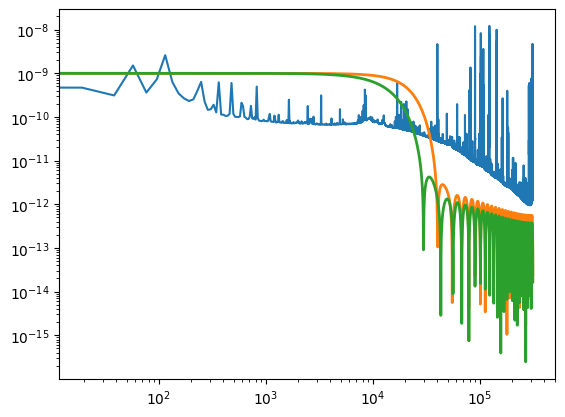

In [4]:
lpf1 = pycrp.filter.LPF_FIR(numtaps=56, cutoff=20e3, fs=FS)
lpf2 = pycrp.filter.LPF_FIR(numtaps=56, cutoff=10e3, fs=FS)


plt.loglog(FFT_FREQ, csds[f"{ch}_{ch}"]/625000/32768*adc2amp )

w, h = lpf1.frequency_response()
plt.plot(w, h*1e-9, color="C1", linewidth=2, label='LPF1')
w, h = lpf2.frequency_response()
plt.plot(w, h*1e-9, color="C2", linewidth=2, label='LPF2')
plt.show()


# 1. Test pulse fitting

(16000.0, 16200.0)

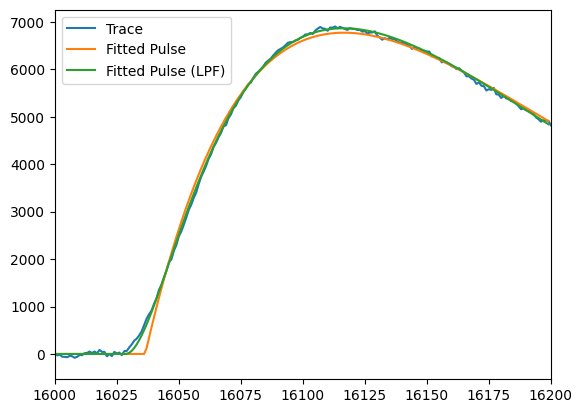

In [31]:
# Test fit_start_time on a sample trace
fitter = pycrp.fit.FitPulse()

i_ch = 0
i_event = 24
# i_event+=1

trace = data[CHANNELS[i_ch]][i_event]
trace = trace - np.mean(trace[:16000])  # Subtract baseline
t0_guess = 16050
tau_rise_guess = 20
tau_fall_guess = 50
loop_bandwidth_normalized = 10_000/625000

result = fitter.fit_pulse(trace[:16200], t0_guess, tau_rise_guess, tau_fall_guess, nfall=1, x_scale=[20,1,2], psd = all_psds[0])
model = fitter.get_model()

result = fitter.fit_pulse(trace[:16200], t0_guess, tau_rise_guess, tau_fall_guess, nfall=1, x_scale=[20,1,2], lpf_corner_freq = loop_bandwidth_normalized, psd = all_psds[i_ch])
model_lpf = fitter.get_model()


plt.plot(trace, label="Trace")
plt.plot(model, label="Fitted Pulse")
plt.plot(model_lpf, label="Fitted Pulse (LPF)")
plt.legend()
plt.xlim(16000, 16200)

In [32]:
reload(pycrp)

<module 'pycrp' from '/home/tomren/repo/pycrp2/src/pycrp/__init__.py'>

In [33]:
# Run fit on all channels

def fit_channels(traces, psds, trace_total, psd_total, len_fit = 200, len_baseline=16000, t0_guess=16050, tau_rise_guess=20, tau_fall_guess=50, loop_bandwidth_normalized=10_000/625000):
    fitter = pycrp.fit.FitPulse()
    nfall = 1
    x_scale = [20,1,2]
    
    
    # 1. Fit on total trace
    result_total = fitter.fit_pulse(trace_total[:t0_guess+len_fit], t0_guess, tau_rise_guess, tau_fall_guess, nfall=nfall, x_scale=x_scale, lpf_corner_freq = loop_bandwidth_normalized, psd = psd_total)
    t0_total, tau_rise_total, tau_fall_total = result_total["params"]["t0"], result_total["params"]["tau_rise"], result_total["params"]["tau_fall"]
    model_total = fitter.get_model()
    
    # 2. Fit on each channel, use total fit as initial guess
    results = []
    models = []
    for ich in range(len(traces)):
        trace = traces[ich]
        psd = psds[ich]
        
        # 2.1 Use total fit as initial guess
        result = fitter.fit_pulse(trace[:int(t0_total)+len_fit], t0_total, tau_rise_total, tau_fall_total, nfall=nfall, x_scale=x_scale, 
                                  lpf_corner_freq = loop_bandwidth_normalized, psd = psd,
                                  bounds = [(t0_total-50, tau_rise_total*0.1, 0), (t0_total+50, tau_rise_total*2, tau_fall_total*2)])
        
        # 2.2 Use the result to do another fit so that the window size is correct, also use a tighter bound on the parameters
        t0_initial, tau_rise_initial, tau_fall_initial = result["params"]["t0"], result["params"]["tau_rise"], result["params"]["tau_fall"]
        result = fitter.fit_pulse(trace[:int(t0_initial)+len_fit], t0_initial, tau_rise_initial, tau_fall_initial, nfall=nfall, x_scale=x_scale, 
                                  lpf_corner_freq = loop_bandwidth_normalized, psd = psd,
                                  bounds = [(t0_initial-10, tau_rise_initial*0.5, 0), (t0_initial+10, tau_rise_initial*2, tau_fall_initial*2)])
        
        results.append(result)
        models.append(fitter.get_model())
        
    return result_total, results, model_total, models

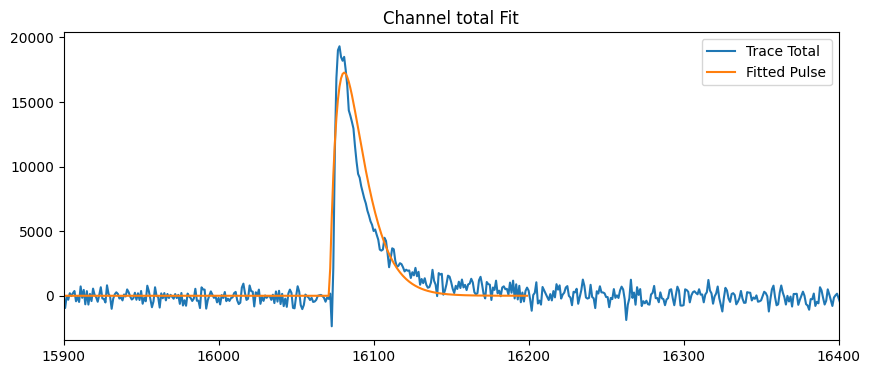

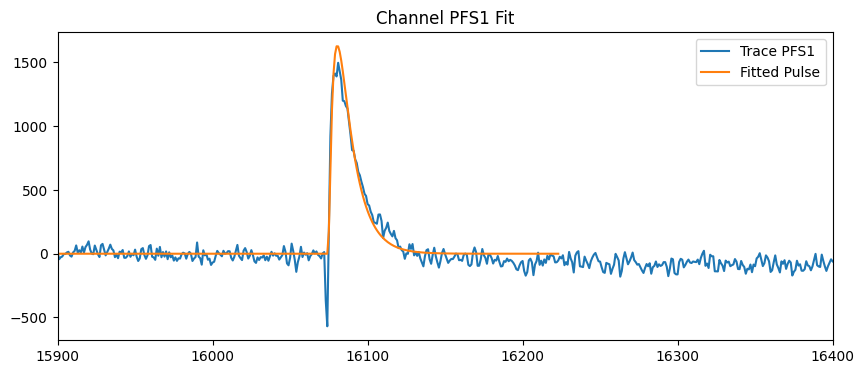

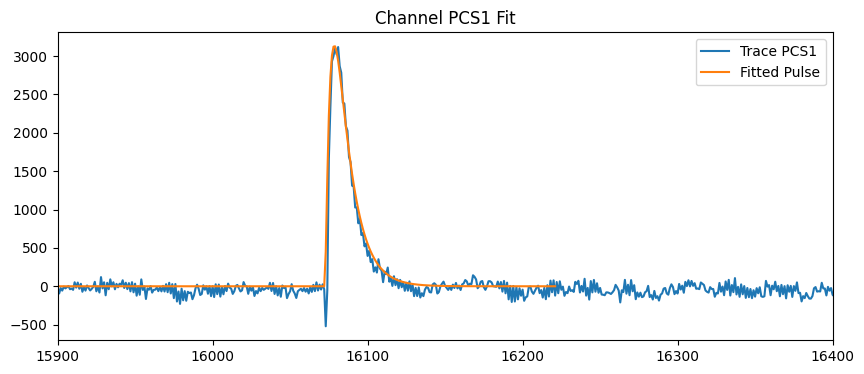

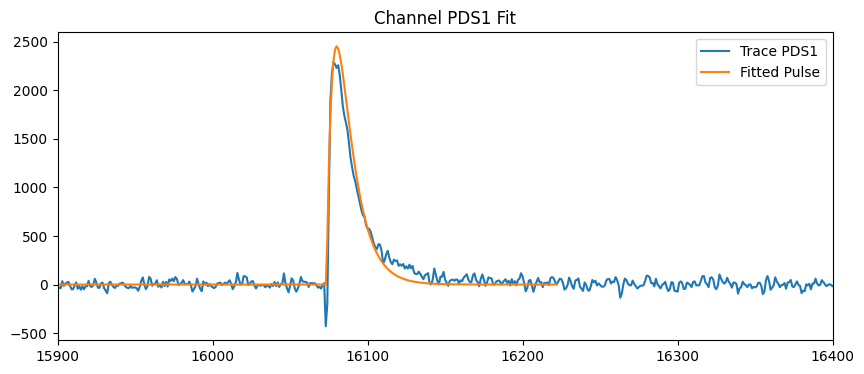

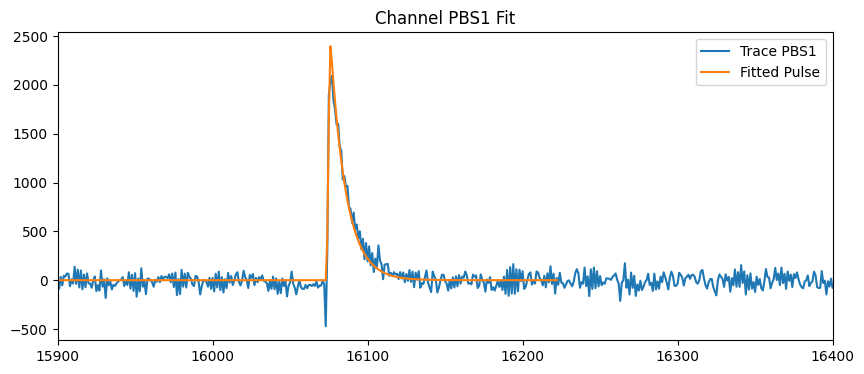

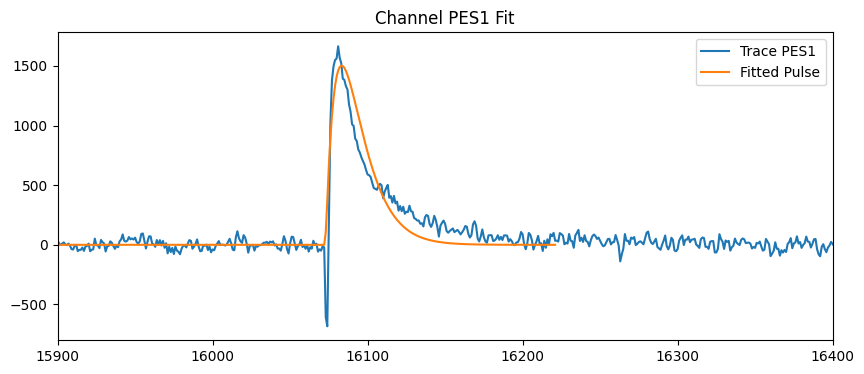

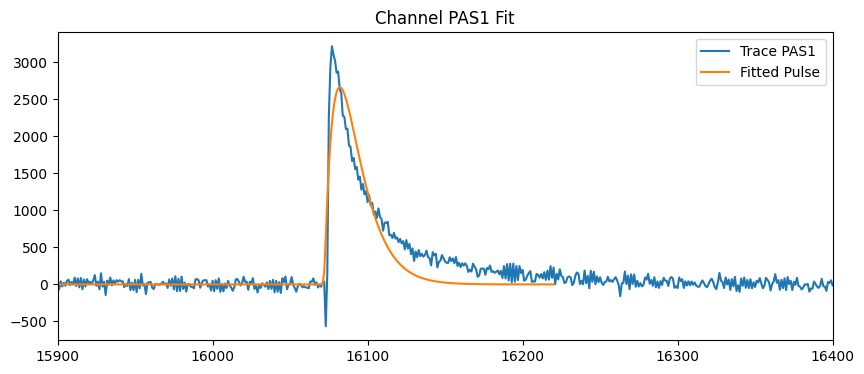

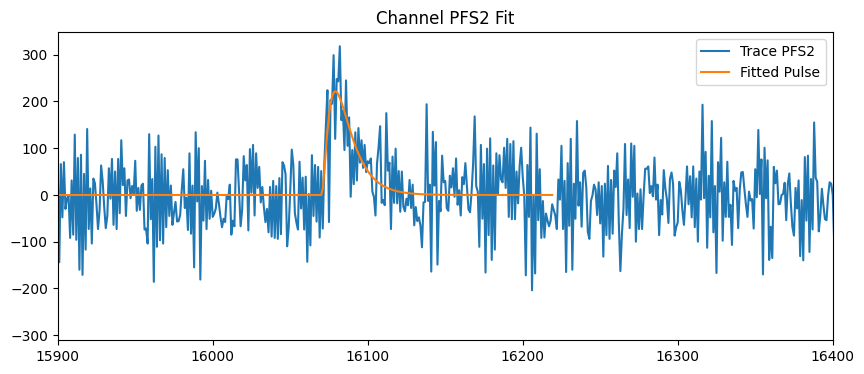

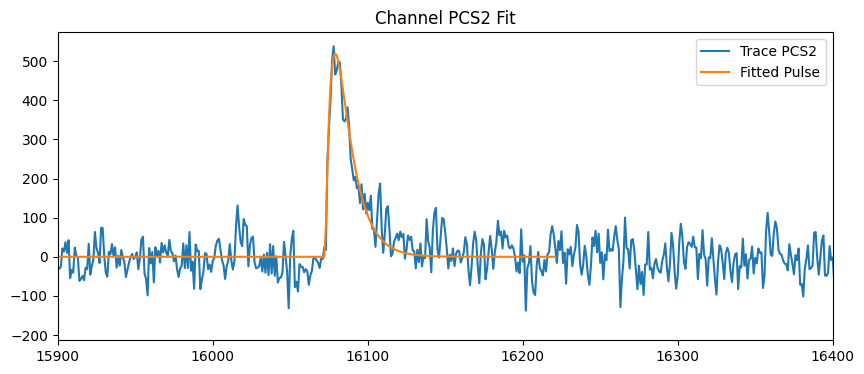

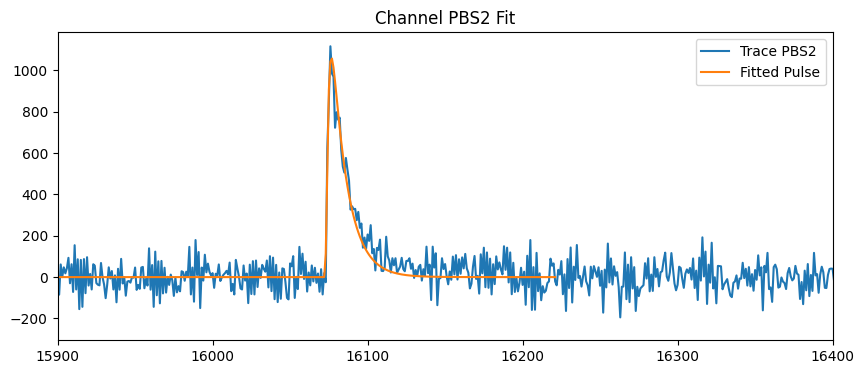

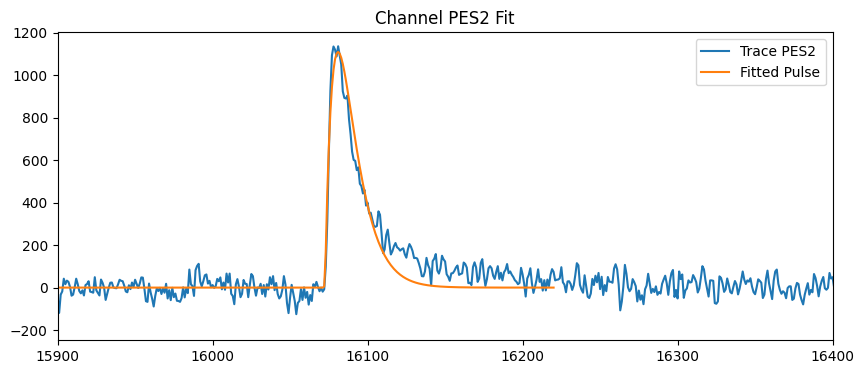

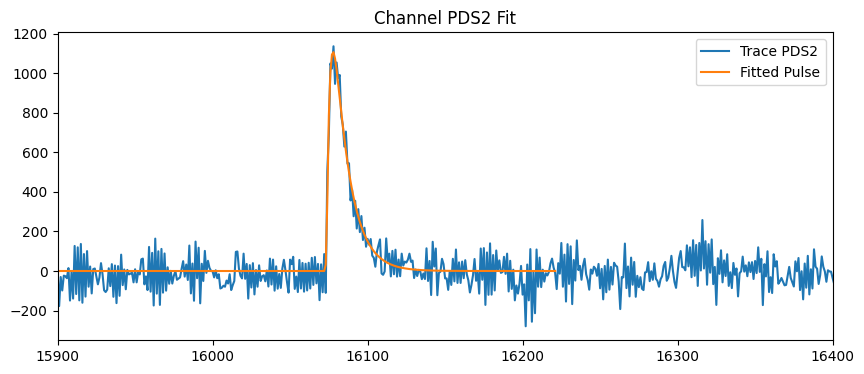

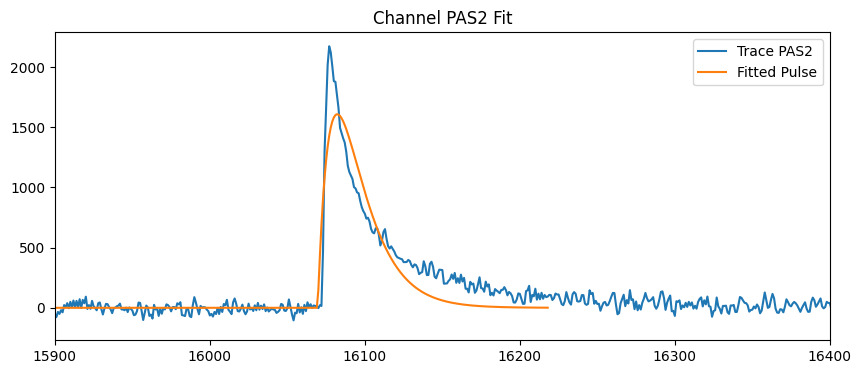

In [34]:
# Test this on one event

i_event = 6
# i_event+=1

traces = []
for i_ch in range(len(CHANNELS)):
    traces.append(data[CHANNELS[i_ch]][i_event])
    traces[i_ch] = traces[i_ch] - np.mean(traces[i_ch][:16000])  # Subtract baseline
    
trace_total = np.sum(traces, axis=0)

result_total, results, model_total, models = fit_channels(traces, all_psds, trace_total, total_psd, len_fit = 150, len_baseline=16000, t0_guess=16050, tau_rise_guess=20, tau_fall_guess=50, loop_bandwidth_normalized=10_000/625000)

# Plot the results
plt.figure(figsize=(10, 4))
plt.plot(trace_total, label=f"Trace Total")
plt.plot(model_total, label="Fitted Pulse")
plt.legend()
plt.xlim(15900, 16400)
plt.title(f"Channel total Fit")
plt.show()


for ich, result in enumerate(results):
    trace = traces[ich]
    model = models[ich]

    plt.figure(figsize=(10, 4))
    plt.plot(trace, label=f"Trace {CHANNELS[ich]}")
    plt.plot(model, label="Fitted Pulse")
    plt.legend()
    plt.xlim(15900, 16400)
    plt.title(f"Channel {CHANNELS[ich]} Fit")
    plt.show()

# 2. Random select a subset of events and run exp fit

In [35]:
of_total = []
for ievent in range(len(data[CHANNELS[0]])):
    if ievent % 100 == 0:
        print(ievent, end="\r")
    time_traces = np.array([np.array(data[key][ievent], dtype=float) for key in CHANNELS]) # (N_channels, N_samples)
    baselines = [np.mean(trace[:LEN_PRE]) for trace in time_traces]
    time_traces_nobaseline = [(time_traces[i]-baselines[i]) * config.weights[i] for i in range(len(time_traces))]
    
    of_total.append(OF_Total.of(np.sum(time_traces_nobaseline, axis=0))[0])
    
of_total = np.array(of_total)

In [36]:
import numpy as np

def sample_uniform_energy(energies, n_samples, n_bins=20, seed=None):
    """
    Randomly sample events to obtain an approximately uniform
    energy distribution, without replacement.

    Parameters
    ----------
    energies : array-like
        Energy of each event.
    n_samples : int
        Desired number of sampled events.
    n_bins : int
        Number of equally spaced energy bins.
    seed : int, optional
        Random seed for reproducibility.

    Returns
    -------
    indices : np.ndarray
        Indices of the selected events.
    """
    energies = np.asarray(energies)
    rng = np.random.default_rng(seed)

    bins = np.linspace(energies.min(), energies.max(), n_bins + 1)
    bin_ids = np.clip(np.digitize(energies, bins) - 1, 0, n_bins - 1)

    # Target approximately equal numbers per bin
    target = np.full(n_bins, n_samples // n_bins)
    target[:n_samples % n_bins] += 1

    selected = []

    for i in range(n_bins):
        candidates = np.where(bin_ids == i)[0]
        n = min(target[i], len(candidates))

        if n > 0:
            selected.extend(rng.choice(candidates, size=n, replace=False))

    return np.array(selected, dtype=int)

Rough number of training events: 727


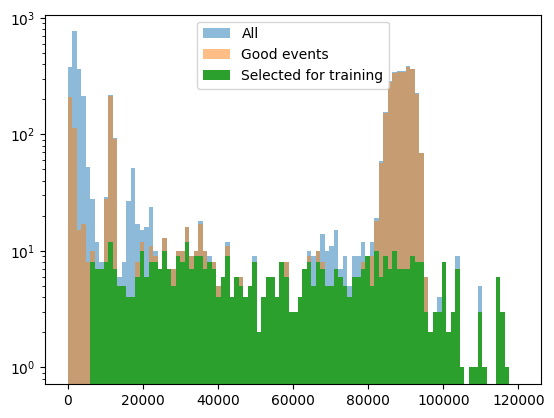

In [37]:
mask_train = mask_good & (of_total>10000)&(of_total<80000) 
print("Rough number of training events:", np.sum(mask_train))

# Select events with a flatter energy distribution
mask_train_real = mask_good & (of_total>6000)
indices = sample_uniform_energy(
    of_total[mask_train_real],
    n_samples=np.sum(mask_train),
    n_bins=100,
    seed=42
)

indices_good = np.flatnonzero(mask_train_real)
indices_train = indices_good[indices]

plt.hist(of_total, bins=100, alpha=0.5,range=(0,120000), label="All");
plt.hist(of_total[mask_good], bins=100, alpha=0.5,range=(0,120000), label="Good events");
plt.hist(of_total[indices_train], bins=100, alpha=1,range=(0,120000), label="Selected for training");
plt.yscale("log")
plt.legend()

In [ ]:
# Prepare container for results
# One per channel
rq_keys = [\
           "fit_t0","fit_amplitude","fit_taurise","fit_taufall", "fit_taufall2", "fit_amplitude2", "fit_chi2", "fit_status",
          ] 
# One per event
rq_keys_singel = [\
          "fit_t0_total","fit_amplitude_total","fit_taurise_total","fit_taufall_total", "fit_taufall2_total", "fit_chi2_total", "fit_status_total",
                 ]
rq = {key:[] for key in rq_keys_singel}
for ch in CHANNELS:
    for key in rq_keys:
        rq[key + "_" + ch] = []
        
        
for ievent, ind in enumerate(indices_train):
    if ievent % 10 == 0:
        print(f"{ievent}/{len(indices_train)}", end="\r")
    time_traces = np.array([np.array(data[key][ind], dtype=float) for key in CHANNELS]) # (N_channels, N_samples)
    baselines = [np.mean(trace[:LEN_PRE]) for trace in time_traces]
    
    time_traces_nobaseline = [time_traces[i]-baselines[i] for i in range(len(time_traces))]
    trace_sum = np.sum(time_traces_nobaseline, axis=0)
    
    result_total, results, model_total, models = fit_channels(time_traces_nobaseline, all_psds, trace_sum, total_psd, len_fit = 150, len_baseline=16000, t0_guess=16050, tau_rise_guess=20, tau_fall_guess=50, loop_bandwidth_normalized=10_000/625000)
    
    for ich, ch in enumerate(CHANNELS):
        result = results[ich]
        rq["fit_t0_" + ch].append(result["params"]["t0"])
        rq["fit_amplitude_" + ch].append(result["params"]["amplitude"])
        rq["fit_taurise_" + ch].append(result["params"]["tau_rise"])
        rq["fit_chi2_" + ch].append(result["cost"]/FS**2*4)
        rq["fit_status_" + ch].append(result["status"])    


for key in rq:
    rq[key] = np.array(rq[key])

In [ ]:
# Save fit result
# joblib.dump(rq, "../data/pca/fit_results_543.joblib")


# Save traces
# traces_pca = {ch:[] for ch in CHANNELS}
# for ievent, ind in enumerate(indices_train):
#     for ch in CHANNELS:
#         traces_pca[ch].append(data[ch][ind])
# joblib.dump(traces_pca, "../data/pca/traces_pca_543.joblib")

['../data/pca/traces_pca_543.joblib']

# 3. PCA

In [5]:
rq = joblib.load("../data/pca/fit_results_543.joblib")
traces_pca = joblib.load("../data/pca/traces_pca_543.joblib")

In [6]:
# 1. Get a list of good events based on fit status
mask_good_fit = np.ones(len(rq["fit_status_" + CHANNELS[0]]), dtype=bool)
for ch in CHANNELS:
    mask_good_fit &= (rq["fit_status_" + ch] > 0)
print(sum(mask_good_fit), "good events out of", len(mask_good_fit))

# 2. Align the traces based on the fitted t0 and subtract the baseline
# Get a mean value of the fitted t0 for all channel
t0s = np.array([rq["fit_t0_" + ch] for ch in CHANNELS])
t0_mean = np.mean(t0s)
traces_pca_aligned = {ch:[] for ch in CHANNELS}
print("Aligning traces based on fitted t0 to the mean value of t0 all channels")
print("Mean t0:", t0_mean)

for ievent in range(len(traces_pca[CHANNELS[0]])):
    if not mask_good_fit[ievent]:
        continue
    for ich, ch in enumerate(CHANNELS):
        trace = traces_pca[ch][ievent]
        baseline = np.mean(trace[:LEN_PRE])
        trace_nobaseline = trace - baseline
        t0_fit = rq["fit_t0_" + ch][ievent]
        shift = int(t0_mean - t0_fit)
        trace_aligned = np.roll(trace_nobaseline, shift)
        traces_pca_aligned[ch].append(trace_aligned)



543 good events out of 543
Aligning traces based on fitted t0 to the mean value of t0 all channels
Mean t0: 16024.811219638119


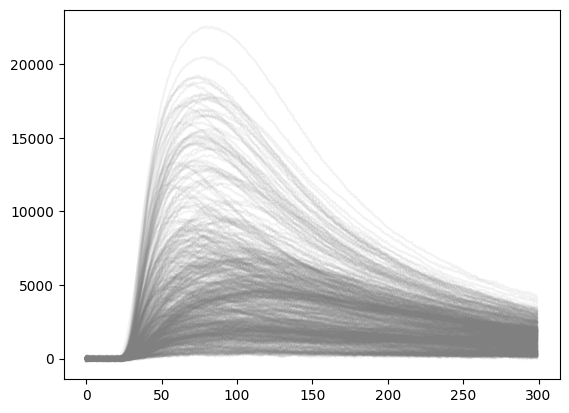

In [7]:
ch = CHANNELS[2]
ch = "PCS1"
for trace in traces_pca_aligned[ch]:
    plt.plot(trace[16000:16300], alpha=0.1, color="grey")


## 3.1 Iterate on average pulse to get ~zero residual

In [8]:
ich = 0

residuals_all = {}
template_average_all = {}

for ich, ch in enumerate(CHANNELS):
    print(ch)
    ch = CHANNELS[ich]
    N_ITER = 5
    RESIDUALS = []
    RESIDUALS_MEAN = []
    AMPLITUDES = []
    TEMPLATES = []

    template_0 = np.mean([traces_pca_aligned[ch][i] / max(traces_pca_aligned[ch][i]) for i in range(len(traces_pca_aligned[ch]))], axis=0)
    template_0/= np.max(template_0)
    OF_OBJECT = pycrp.filter.OF(template_0, all_psds[ich], fs = 1, lowfreq_chi2_bins =100)
    amplitudes = [OF_OBJECT.of(traces_pca_aligned[ch][i])[0] for i in range(len(traces_pca_aligned[ch]))]


    for iter in range(N_ITER):
        # 1. Get the mean template
        template = np.mean([traces_pca_aligned[ch][i] / amplitudes[i] for i in range(len(traces_pca_aligned[ch]))], axis=0)
        template/= np.max(template)
        TEMPLATES.append(template)
        
        # 2. Get the amplitudes using OF0
        OF_OBJECT = pycrp.filter.OF(template, all_psds[ich], fs = 1, lowfreq_chi2_bins =100)
        amplitudes = [OF_OBJECT.of0(traces_pca_aligned[ch][i])[0] for i in range(len(traces_pca_aligned[ch]))]
        AMPLITUDES.append(amplitudes)
        
        # 3. Get the residuals
        residuals = [traces_pca_aligned[ch][i]/amplitudes[i] - template for i in range(len(traces_pca_aligned[ch]))]
        if iter == N_ITER-1:
            RESIDUALS = np.array(residuals)
        RESIDUALS_MEAN.append(np.mean(residuals, axis=0))
        print(f"{iter} Max residual:", max(abs(RESIDUALS_MEAN[-1])))
        
        
    residuals_all[ch] = RESIDUALS
    template_average_all[ch] = template



PFS1
0 Max residual: 0.0016911032350114313
1 Max residual: 2.2477101934714892e-05
2 Max residual: 3.04471343254665e-07
3 Max residual: 4.146697790543417e-09
4 Max residual: 5.670873449565363e-11
PCS1
0 Max residual: 0.0010900399585608484
1 Max residual: 3.7837689288964e-05
2 Max residual: 2.2809947192892303e-06
3 Max residual: 1.7901927927491069e-07
4 Max residual: 1.8192367746074898e-08
PDS1
0 Max residual: 0.001248538426508164
1 Max residual: 3.4259982343957926e-05
2 Max residual: 1.2845322636306584e-06
3 Max residual: 5.0759107734985426e-08
4 Max residual: 2.126982134619266e-09
PBS1
0 Max residual: 0.0010550949106935708
1 Max residual: 2.4047531510837826e-05
2 Max residual: 6.913689570007952e-07
3 Max residual: 2.0215854084353494e-08
4 Max residual: 5.927697878283201e-10
PES1
0 Max residual: 0.0013634160110243543
1 Max residual: 4.104477448565169e-05
2 Max residual: 1.7146770085482706e-06
3 Max residual: 7.250104420911942e-08
4 Max residual: 3.0665961563625642e-09
PAS1
0 Max residua

### Plot an example of how the average residual change in each iteration

149.5633211991751 -6.357955463954984e-09 -2.591878579008415e-10 1.0


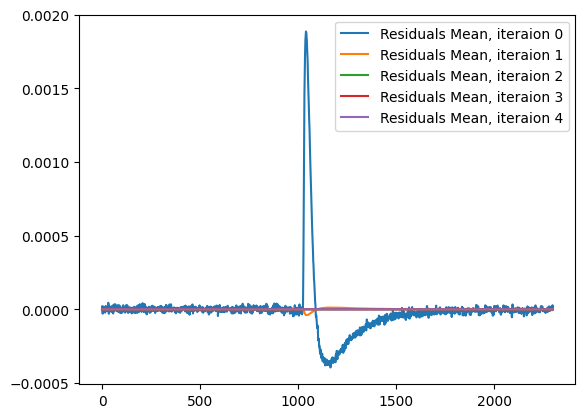

In [9]:
for iter, r in enumerate(RESIDUALS_MEAN):
    plt.plot(r[15000:17300], label=f'Residuals Mean, iteraion {iter}')
plt.legend()
print(np.dot(template, template), np.dot(template, RESIDUALS_MEAN[-1]), OF_OBJECT.of(RESIDUALS_MEAN[-1])[0], OF_OBJECT.of(template)[0])

### Example of the window function

/tmp/ipykernel_637497/1282725466.py:12: RuntimeWarning: overflow encountered in exp
  window_y *= 1/(1 + np.exp(-(window_x-ind_start + 70)/10)) # sigmoid function to smoothly transition from 1 to 0


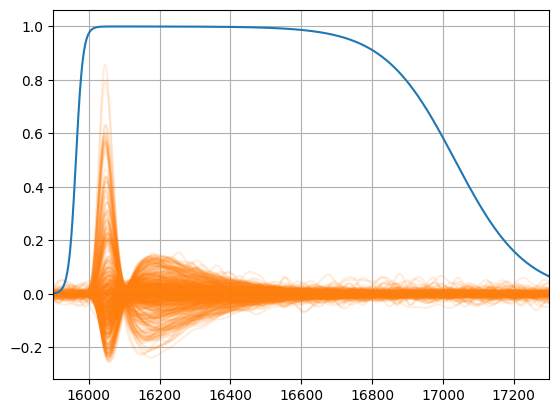

In [10]:
RESIDUALS_LPF = np.array([lpf2(r, cutoff=10e3) for r in RESIDUALS])

x = np.arange(len(RESIDUALS_LPF[0]))
for r in RESIDUALS_LPF:
    plt.plot(x[15900:17300], r[15900:17300], alpha=0.13, color="C1")
    
    
loop_delay = 625000/10e3/2/3.1415
ind_start = int(t0_mean+loop_delay)
window_x = np.arange(len(RESIDUALS_LPF[0]))
window_y = 1/(1 + np.exp((window_x-ind_start-1000)/100))# sigmoid function to smoothly transition from 0 to 1
window_y *= 1/(1 + np.exp(-(window_x-ind_start + 70)/10)) # sigmoid function to smoothly transition from 1 to 0
plt.plot(window_x,window_y)
plt.xlim(15900, 17300)
plt.grid()

In [11]:
loop_delay = 625000/10e3/2/3.1415
ind_start = int(t0_mean+loop_delay)
window_x = np.arange(len(RESIDUALS[0]))
window_y = 1/(1 + np.exp((window_x-ind_start-1000)/100))# sigmoid function to smoothly transition from 0 to 1
window_y *= 1/(1 + np.exp(-(window_x-ind_start + 25)/10)) # sigmoid function to smoothly transition from 1 to 0


from sklearn.decomposition import PCA

PCA_results = {}
for ch in CHANNELS[:]:
    print(ch)
    
    # Pre-process the residuals by applying a low-pass filter and a window function
    residuals_mod = []
    for r in residuals_all[ch]:
        r1 = lpf1(r, cutoff=20e3)
        r1 = r1*window_y
        residuals_mod.append(r1)
        
    pca = PCA(n_components=8)
    
    # 2. Fit
    pca.fit(residuals_mod)
    PCA_results[ch] = { "pca": pca, "residuals_mean": np.mean(residuals_mod, axis=0) }
    

/tmp/ipykernel_637497/3631522865.py:5: RuntimeWarning: overflow encountered in exp
  window_y *= 1/(1 + np.exp(-(window_x-ind_start + 25)/10)) # sigmoid function to smoothly transition from 1 to 0


PFS1
PCS1
PDS1
PBS1
PES1
PAS1
PFS2
PCS2
PBS2
PES2
PDS2
PAS2


PFS1


<Figure size 800x400 with 0 Axes>

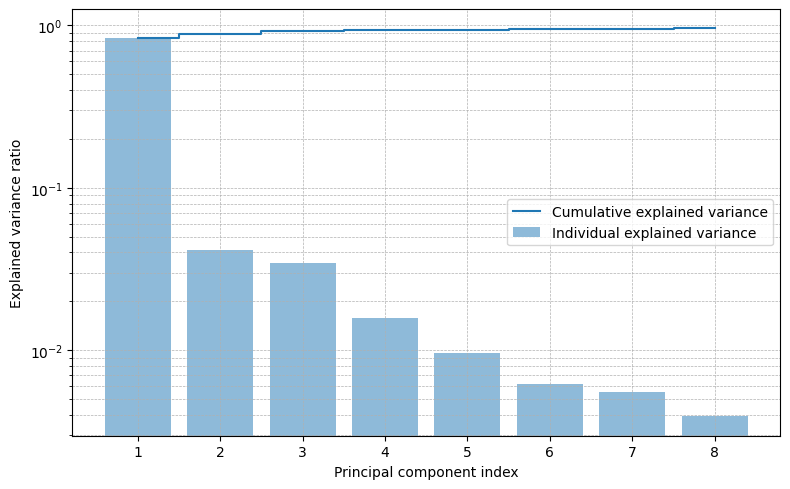

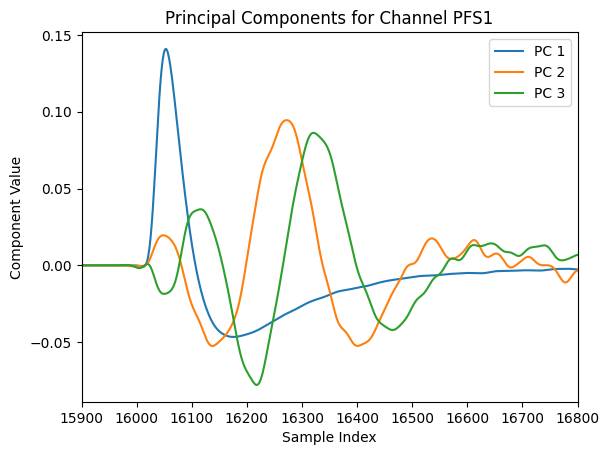

PCS1


<Figure size 800x400 with 0 Axes>

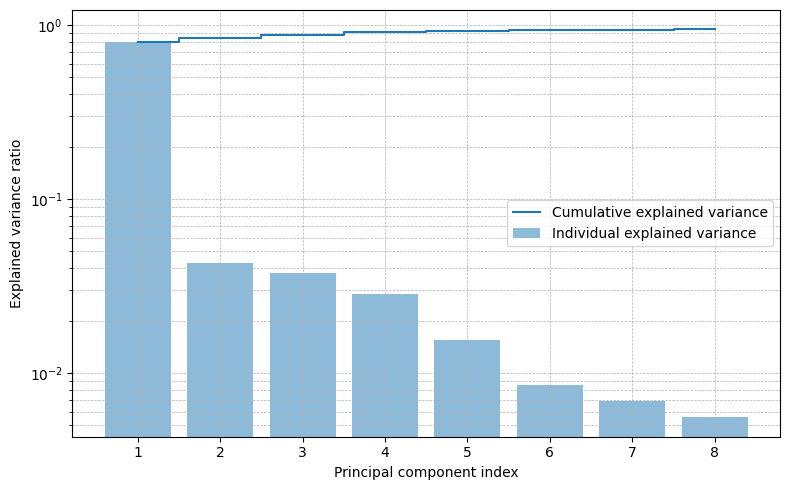

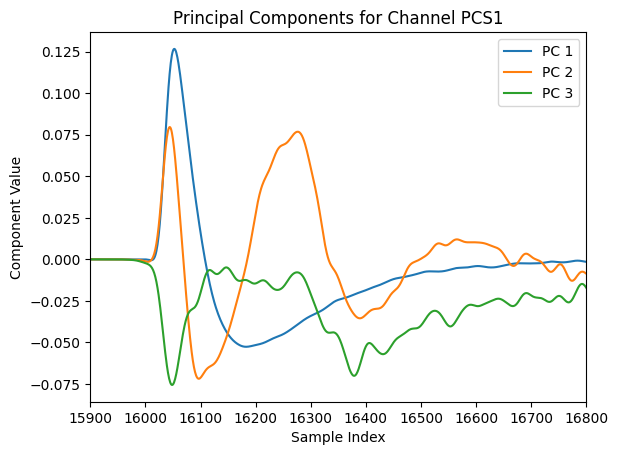

PDS1


<Figure size 800x400 with 0 Axes>

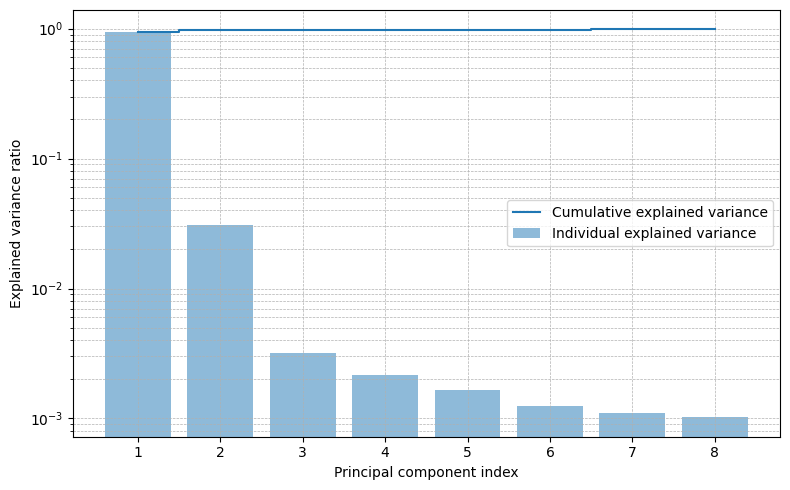

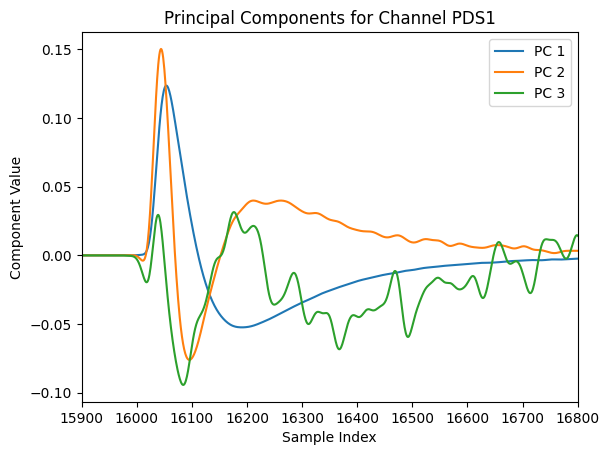

PBS1


<Figure size 800x400 with 0 Axes>

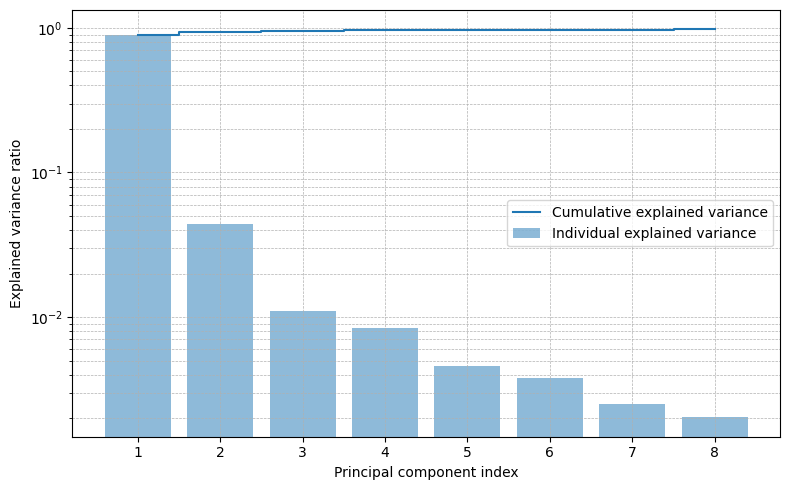

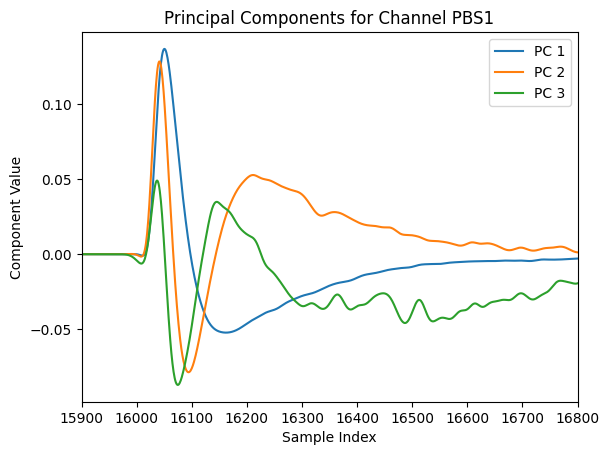

PES1


<Figure size 800x400 with 0 Axes>

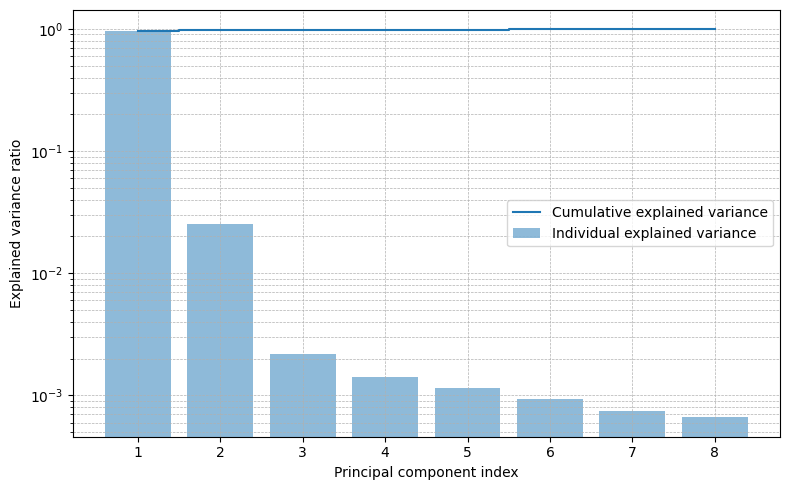

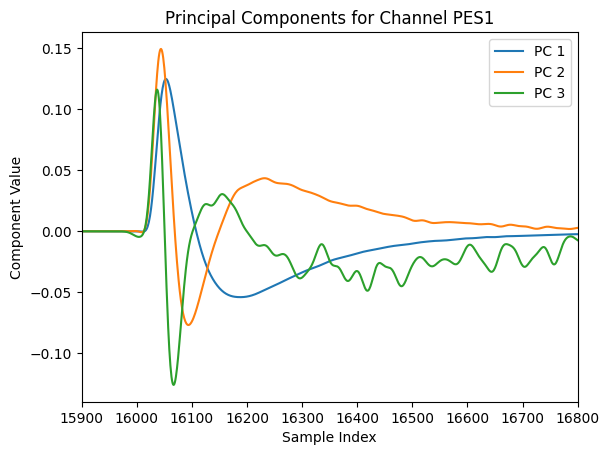

PAS1


<Figure size 800x400 with 0 Axes>

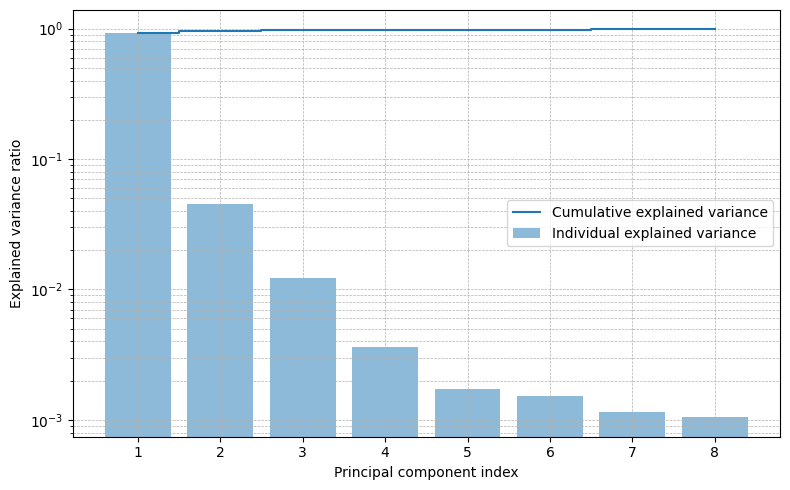

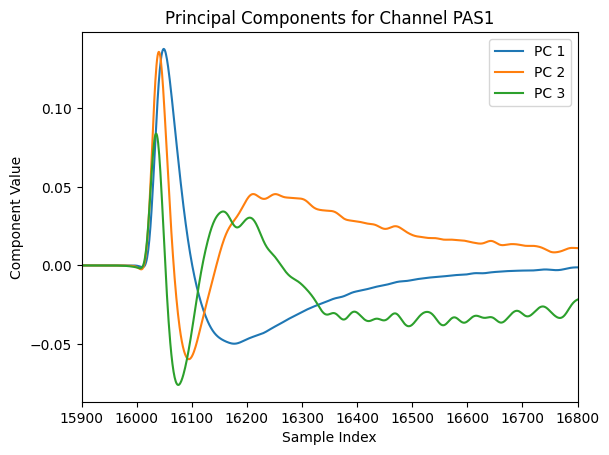

PFS2


<Figure size 800x400 with 0 Axes>

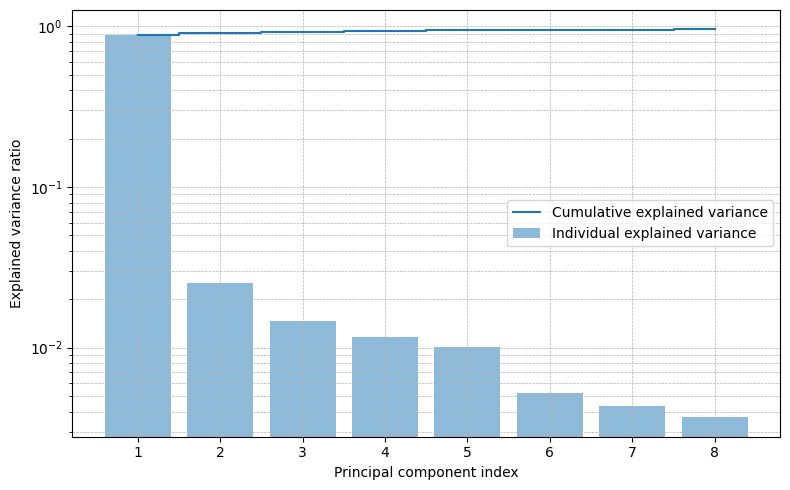

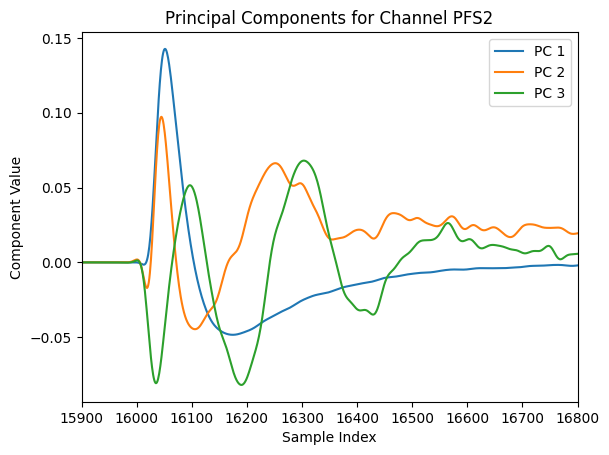

PCS2


<Figure size 800x400 with 0 Axes>

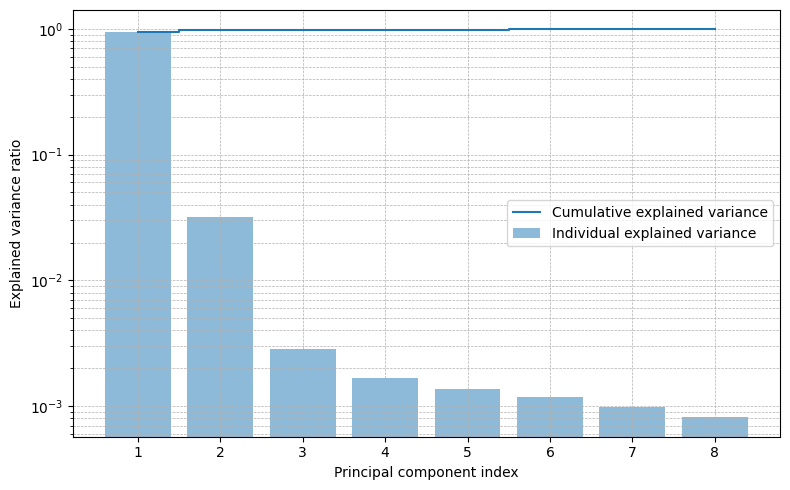

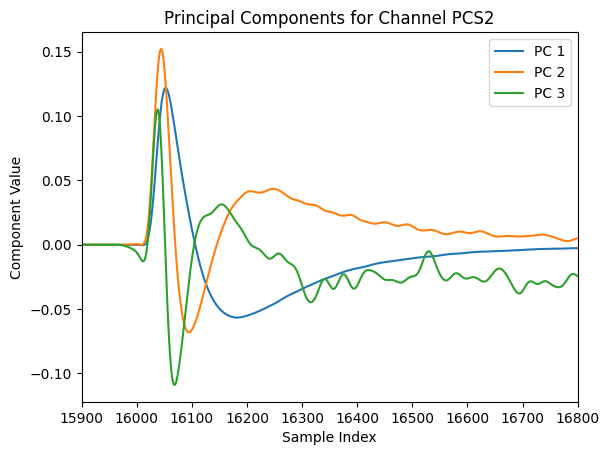

PBS2


<Figure size 800x400 with 0 Axes>

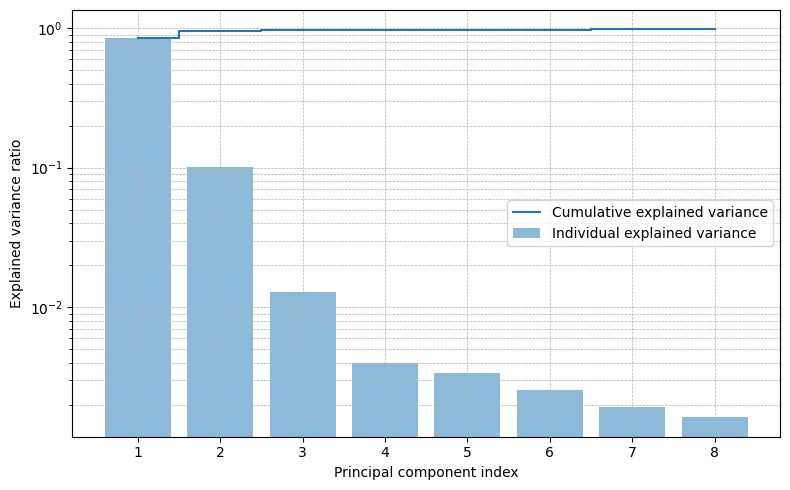

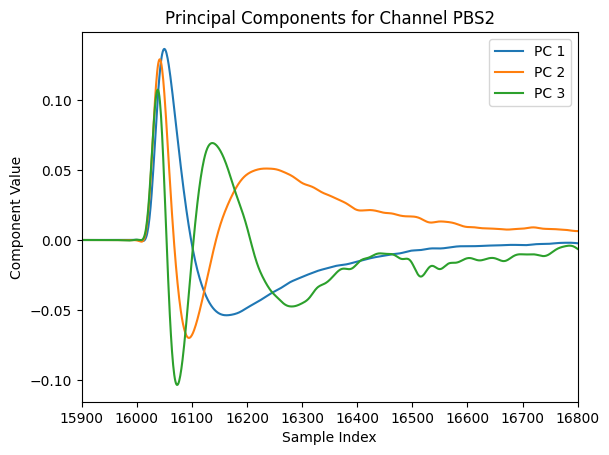

PES2


<Figure size 800x400 with 0 Axes>

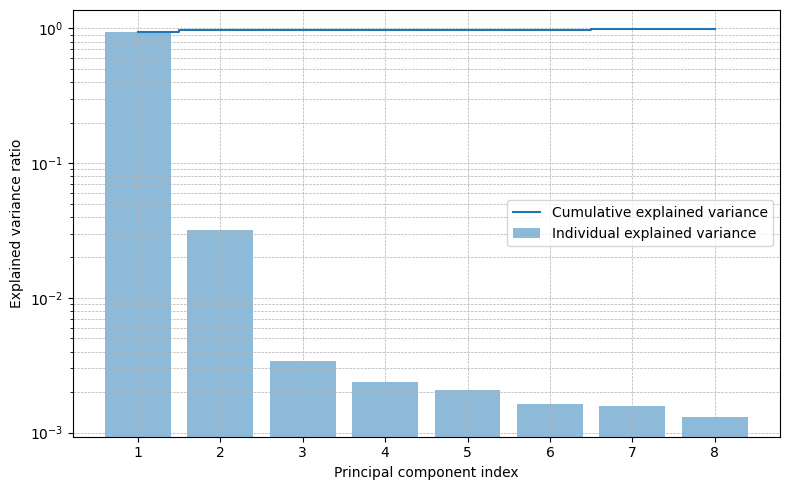

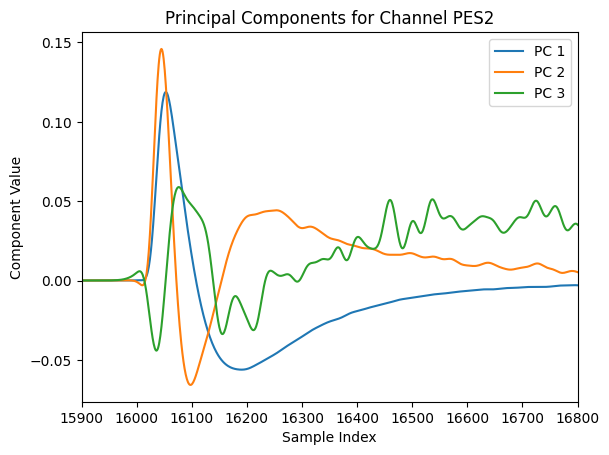

PDS2


<Figure size 800x400 with 0 Axes>

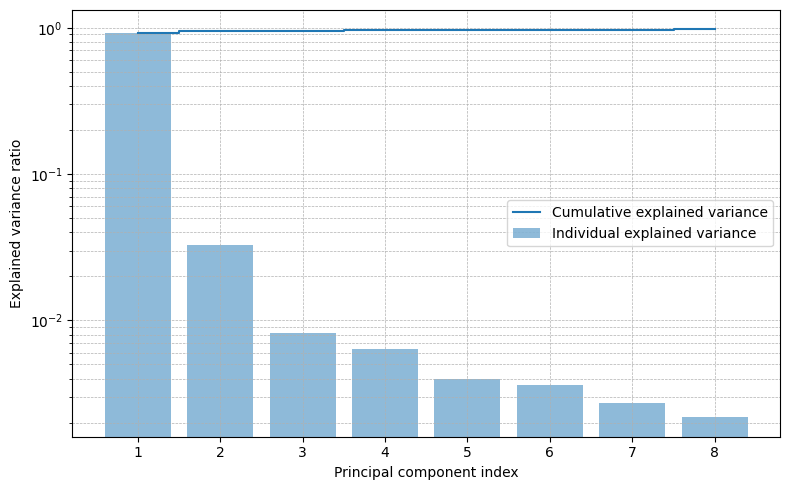

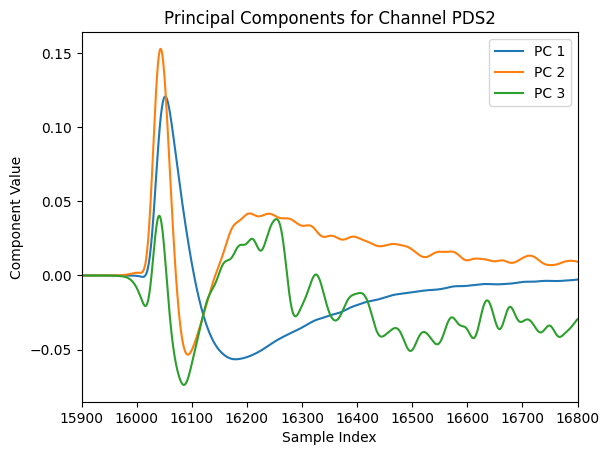

PAS2


<Figure size 800x400 with 0 Axes>

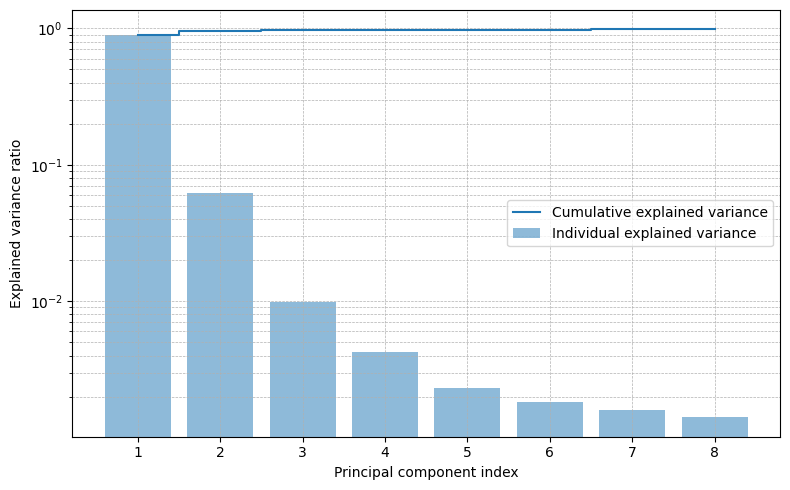

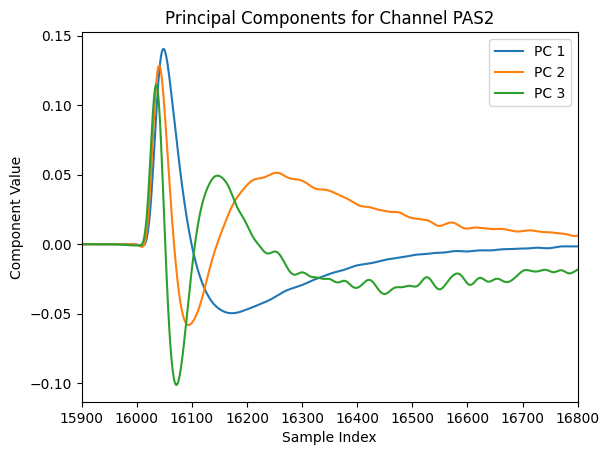

In [12]:
for ch in CHANNELS[:]:
    print(ch)
    pca = PCA_results[ch]["pca"]


    # 3. Extract explained variance ratio
    exp_var_pca = pca.explained_variance_ratio_
    # 4. Cumulative explained variance
    cum_sum_eigenvalues = np.cumsum(exp_var_pca)      

    plt.figure(figsize=(8, 4))
    plt.figure(figsize=(8, 5))
    plt.bar(range(1, len(exp_var_pca) + 1), exp_var_pca, alpha=0.5, align='center', label='Individual explained variance')
    plt.step(range(1, len(cum_sum_eigenvalues) + 1), cum_sum_eigenvalues, where='mid', label='Cumulative explained variance')
    plt.ylabel('Explained variance ratio')
    plt.xlabel('Principal component index')
    plt.legend(loc='best')
    plt.yscale("log")
    plt.tight_layout()
    plt.grid(which='both', linestyle='--', linewidth=0.5)
    plt.show()


    eigenvectors = pca.components_
    for i in range(3):
        plt.plot(eigenvectors[i], label=f"PC {i+1}")

    plt.title(f'Principal Components for Channel {ch}')
    plt.xlabel('Sample Index')
    plt.ylabel('Component Value')
    plt.legend()
    plt.xlim(15800, 17500)
    plt.xlim(15900, 16800)
    plt.show()

In [ ]:
# Save PCA results
joblib.dump(PCA_results, "../data/pca/PCA_results_543.joblib")

['../data/pca/PCA_results_543.joblib']

In [18]:
# Save templates
templates_pca = {"template_avg":{}, 
                 "template_pca":{},
                 "variance_pca":{},
                 "metadata": {"len_trace": LEN_TRACE, "len_pre": LEN_PRE, "template_t0": t0_mean, "template_LPF_Hz": 10e3, "fs": FS, "dt": dt, "adc2amp": adc2amp, }}
N_PCs = 3
for ch in CHANNELS:
    templates_pca["template_avg"][ch] = template_average_all[ch]
    templates_pca["template_pca"][ch] = PCA_results[ch]["pca"].components_[:N_PCs]
    templates_pca["variance_pca"][ch] = PCA_results[ch]["pca"].explained_variance_[:N_PCs]

In [19]:
joblib.dump(templates_pca, "../data/pca/templates_pca_543.joblib")

['../data/pca/templates_pca_543.joblib']

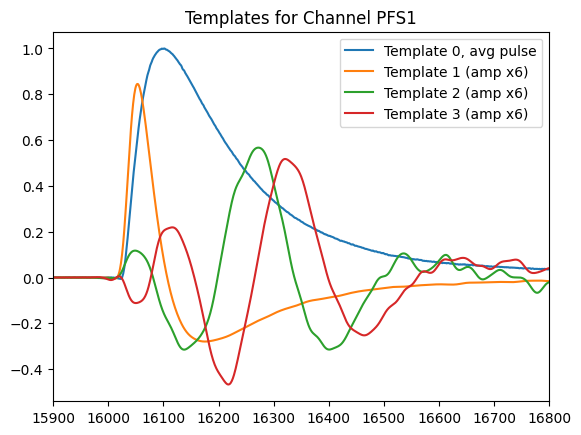

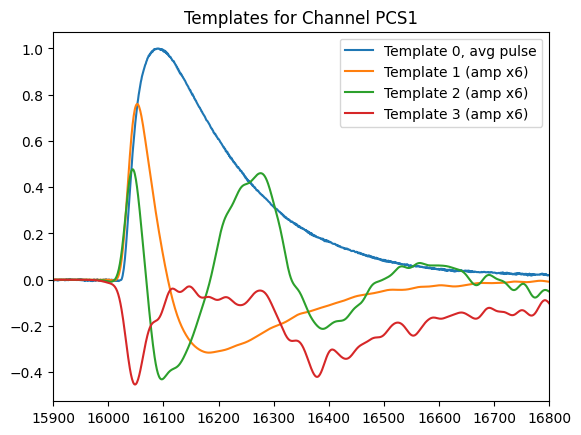

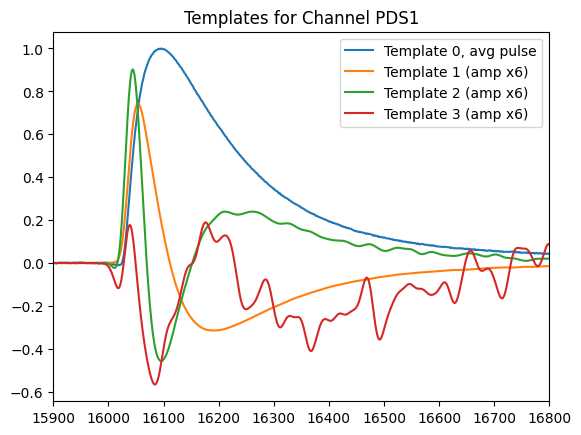

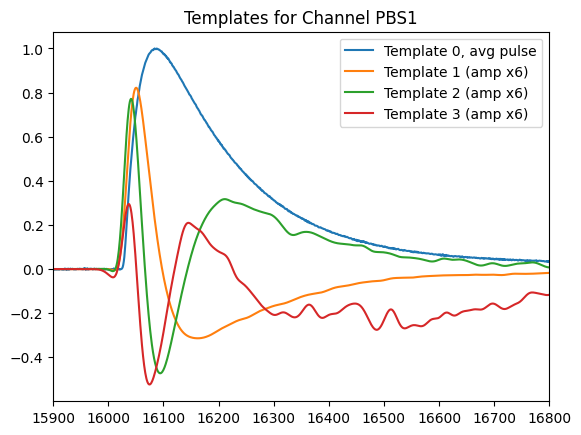

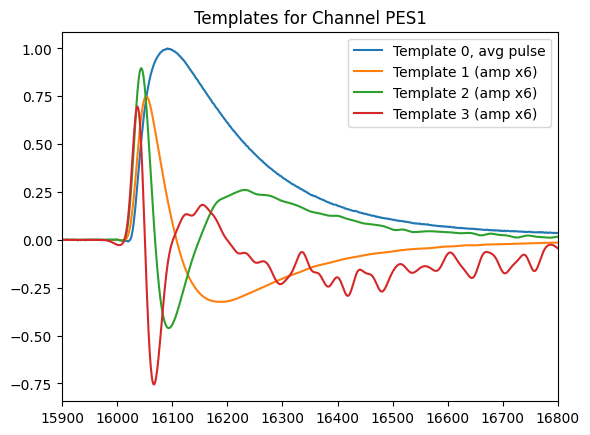

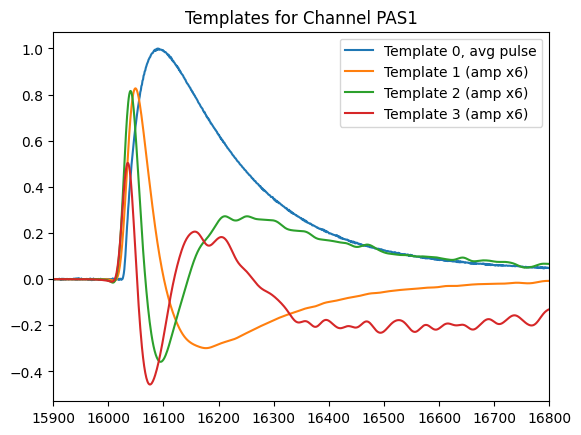

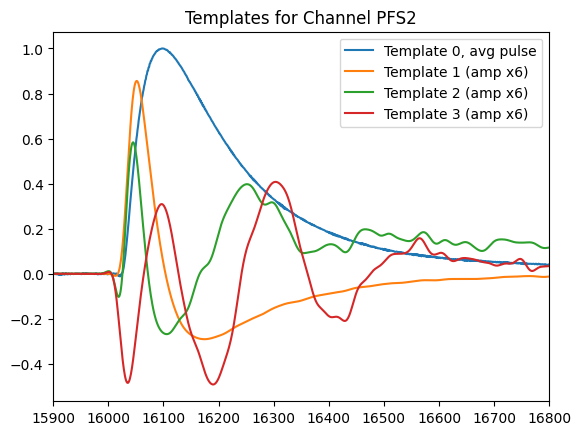

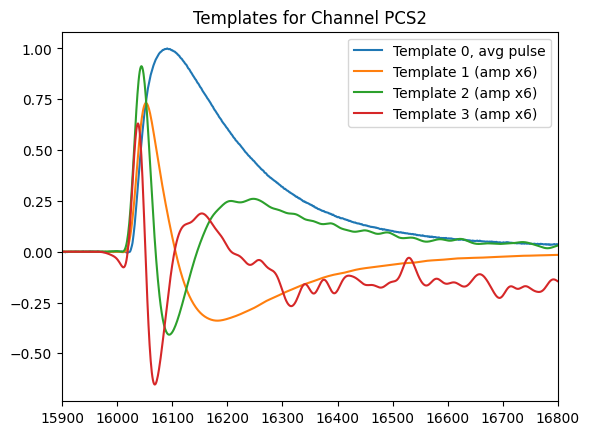

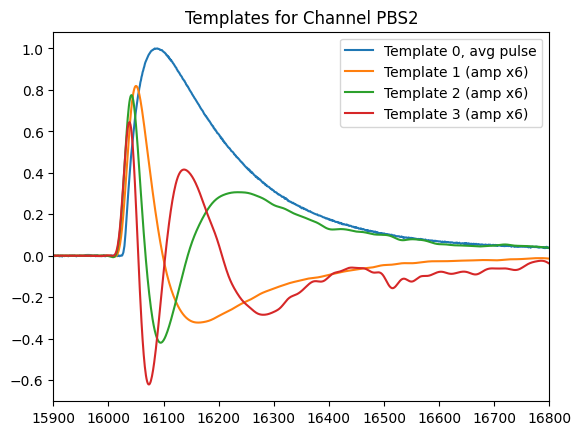

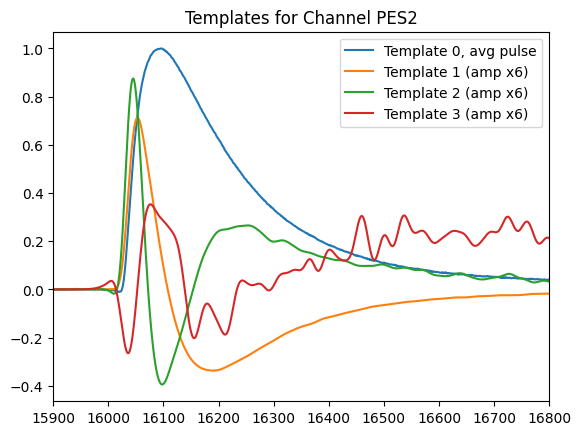

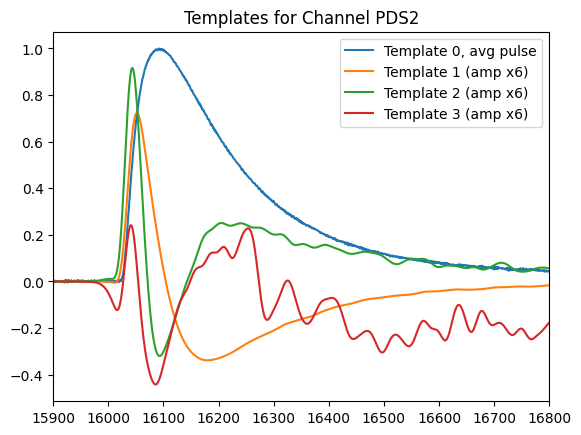

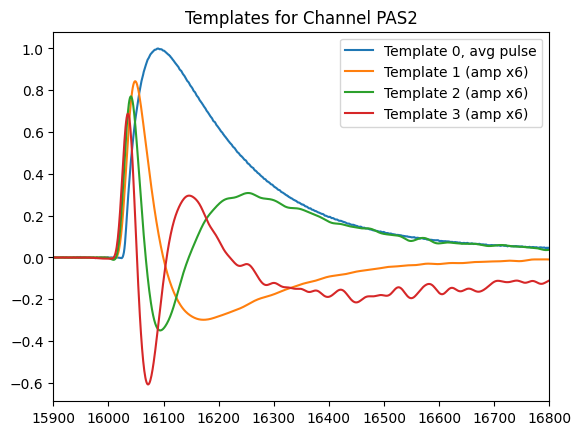

In [22]:
for ch in CHANNELS:
    plt.plot(templates_pca["template_avg"][ch], label="Template 0, avg pulse")
    for i, t in enumerate(templates_pca["template_pca"][ch]):
        plt.plot(t*6, label=f"Template {i+1} (amp x6)")
    plt.legend()
    plt.xlim(15900, 16800)
    plt.title(f"Templates for Channel {ch}")
    plt.show()